<a href="https://colab.research.google.com/github/ariefshidiq4113-ux/PM_TuRi4_Clustering/blob/main/TuRi4_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Membuat dataset sintetis segmentasi pelanggan
np.random.seed(42)
n_samples = 200

usia = np.random.randint(18, 70, size=n_samples)
pendapatan = np.random.randint(15, 140, size=n_samples) # dalam jutaan
skor_belanja = np.random.randint(1, 100, size=n_samples)

df = pd.DataFrame({
    'usia': usia,
    'pendapatan': pendapatan,
    'skor_belanja': skor_belanja
})

In [ ]:
# ==========================================
# LANGKAH 1 — Menyiapkan data & scaling (wajib)
# ==========================================
X_scaled = StandardScaler().fit_transform(df)

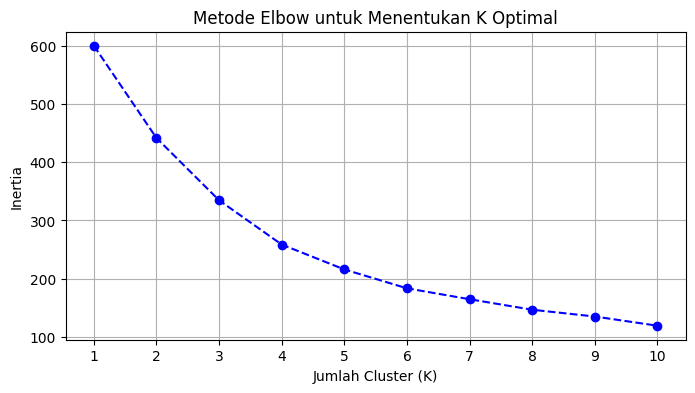

In [ ]:
# ==========================================
# LANGKAH 2 — Metode Elbow menentukan K
# ==========================================
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), inertias, marker='o', color='b', linestyle='--')
plt.title('Metode Elbow untuk Menentukan K Optimal')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [ ]:
# ==========================================
# LANGKAH 3 — Menjalankan K-Means (K=3)
# ==========================================
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

In [ ]:
# ==========================================
# LANGKAH 4 — Evaluasi Silhouette Score
# ==========================================
score_k3 = silhouette_score(X_scaled, df['cluster'])
print(f"Silhouette Score (K=3): {score_k3:.4f}")
print("-" * 40)

Silhouette Score (K=3): 0.2742
----------------------------------------


In [ ]:
# ==========================================
# LANGKAH 5 — Interpretasi & Profiling Cluster
# ==========================================
profil = df.groupby('cluster')[['usia', 'pendapatan', 'skor_belanja']].mean().round(1)

# Memberi penamaan/penafsiran profil segmen
nama_cluster = {
    0: 'Pelanggan Setia / High-Spender',
    1: 'Pelanggan Hemat / Low-Spender',
    2: 'Pelanggan Pasif / Target Potensial'
}
profil['segmen_pelanggan'] = profil.index.map(nama_cluster)
print("Profil Rata-rata Tiap Cluster:")
print(profil)

Profil Rata-rata Tiap Cluster:
         usia  pendapatan  skor_belanja                    segmen_pelanggan
cluster                                                                    
0        30.5       106.8          52.1      Pelanggan Setia / High-Spender
1        42.9        42.8          60.3       Pelanggan Hemat / Low-Spender
2        58.5        98.7          30.9  Pelanggan Pasif / Target Potensial


In [ ]:
# --- Latihan 1: Jalankan K-Means K=5 pada X_scaled ---
kmeans_k5 = KMeans(n_clusters=5, random_state=42, n_init=10)
cluster_k5 = kmeans_k5.fit_predict(X_scaled)
score_k5 = silhouette_score(X_scaled, cluster_k5)

In [ ]:
# --- Latihan 2: Jalankan K-Means K=3 TANPA scaling ---
kmeans_no_scale = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_no_scale = kmeans_no_scale.fit_predict(df[['usia', 'pendapatan', 'skor_belanja']])
score_no_scale = silhouette_score(df[['usia', 'pendapatan', 'skor_belanja']], cluster_no_scale)

print(f"Silhouette Score K=3 (dengan scaling) : {score_k3:.4f}")
print(f"Silhouette Score K=5 (dengan scaling) : {score_k5:.4f}")
print(f"Silhouette Score K=3 (tanpa scaling)  : {score_no_scale:.4f}")

Silhouette Score K=3 (dengan scaling) : 0.2742
Silhouette Score K=5 (dengan scaling) : 0.3052
Silhouette Score K=3 (tanpa scaling)  : 0.3412


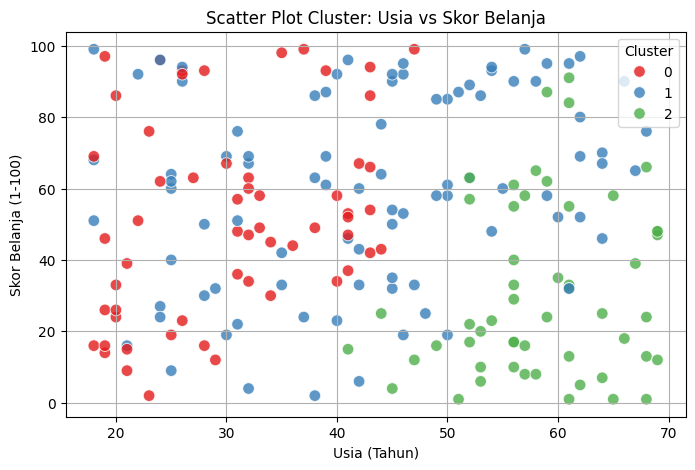

In [ ]:
# --- Latihan 3: Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y) ---
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='usia',
    y='skor_belanja',
    hue='cluster',
    palette='Set1',
    s=70,
    alpha=0.8
)

plt.title('Scatter Plot Cluster: Usia vs Skor Belanja')
plt.xlabel('Usia (Tahun)')
plt.ylabel('Skor Belanja (1-100)')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

# Refleksi
1. Bagaimana K-Means menemukan kelompok tanpa label?

K-Means bekerja secara teriterasi (iterative optimization):   Menginisialisasi K titik sebagai centroid awal secara acak.  
Assignment: Mengelompokkan setiap titik data ke centroid terdekat berdasarkan kalkulasi jarak (seperti jarak Euclidean).
Update: Menghitung ulang nilai rata-rata dari seluruh titik dalam satu kelompok untuk memperbarui posisi centroid.
Proses berulang hingga posisi centroid tidak mengalami perubahan signifikan (konvergen).

2. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?
  
  Siku pada grafik Elbow (point of inflection) terbentuk pada titik di mana penambahan nilai K tidak lagi memberikan penurunan inertia (total jarak kuadrat data ke centroid-nya) secara drastis. Pada titik K=3, kompromi antara kompleksitas jumlah kelompok dan tingkat kerapatan kelompok telah optimal.

3. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?

  K-Means sepenuhnya berbasis perhitungan jarak matematis. Scaling penting untuk memutakhirkan rentang semua fitur ke dalam skala yang setara (misal: mean=0, std=1). Jika dilewatkan, fitur dengan rentang/skala variabel berukuran besar akan mendominasi bobot kalkulasi jarak, sehingga fitur ber-skala kecil menjadi tidak berpengaruh secara adil dalam proses pengelompokan.